# Machine Learning Assignment: Adult Income Classification

**Student:** Bhupendra Kumar  
**BITS ID:** 2026CT05174  
**BITS Email:** 2026ct05174@wilp.bits-pilani.ac.in  
**Course:** Machine Learning  

## Problem statement
Build and compare five classification algorithms on the same public dataset. The goal is to predict whether a person's annual income is `>50K` or `<=50K`. The workflow covers data understanding, missing-value and duplicate handling, preprocessing, stratified 80:20 splitting, training, evaluation, visualization, model saving, and generation of `test_data.csv`.

> Academic-integrity note: Review, understand, execute, and personalize this notebook before submission. Add your own BITS Virtual Lab screenshot, GitHub URL, execution outputs, and observations.

## 1. Dataset choice and justification

This project uses the **Adult Census Income** dataset available through OpenML (original source: UCI Machine Learning Repository).

- Public classification dataset
- Approximately 48,842 instances
- 14 input features, satisfying the minimum of 12
- Mix of numerical and categorical features
- Contains missing markers in categorical columns
- Binary target: `class`
- Suitable for comparing linear, tree, distance-based, probabilistic, and ensemble classifiers

The dataset was selected because it satisfies the size and feature requirements and requires realistic preprocessing.

In [1]:
# Run once in the BITS Virtual Lab if packages are missing:
# !pip install -r requirements.txt

import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix,
    classification_report, RocCurveDisplay
)

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
os.makedirs('model', exist_ok=True)

print('Libraries imported successfully.')

Libraries imported successfully.


## 2. Load and inspect the dataset

`fetch_openml` downloads the public dataset automatically, so no local dataset path is required. Internet access is needed the first time it runs; scikit-learn then caches the dataset.

In [2]:
adult = fetch_openml(name='adult', version=2, as_frame=True, parser='auto')
df = adult.frame.copy()

# Standardize missing markers and target text.
df = df.replace(['?', ' ?'], np.nan)
df['class'] = df['class'].astype(str).str.strip().str.replace('.', '', regex=False)

print('Shape:', df.shape)
display(df.head())
print('\nColumn data types:')
display(df.dtypes.to_frame('dtype'))

Shape: (48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K



Column data types:


,dtype
age,int64
workclass,category
fnlwgt,int64
education,category
education-num,int64
marital-status,category
occupation,category
relationship,category
race,category
sex,category


In [3]:
# Dataset quality checks
print('Missing values by column:')
display(df.isna().sum().sort_values(ascending=False).to_frame('missing_count'))

print('Number of duplicate rows before removal:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after duplicate removal:', df.shape)

print('Target distribution:')
class_counts = df['class'].value_counts()
class_percent = df['class'].value_counts(normalize=True).mul(100).round(2)
display(pd.DataFrame({'count': class_counts, 'percentage': class_percent}))

Missing values by column:


,missing_count
occupation,2809
workclass,2799
native-country,857
fnlwgt,0
education,0
education-num,0
age,0
marital-status,0
relationship,0
sex,0


Number of duplicate rows before removal: 52
Shape after duplicate removal: (48790, 15)
Target distribution:


,count,percentage
class,,
<=50K,37109,76.06
>50K,11681,23.94


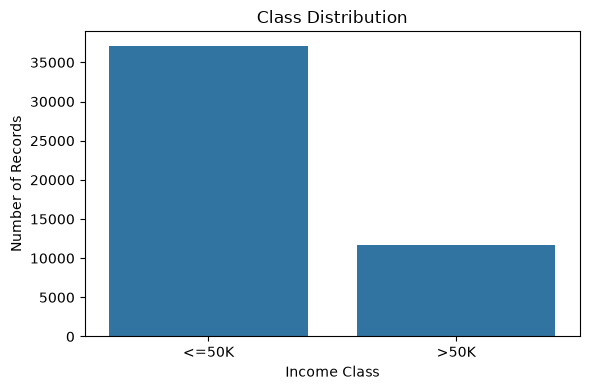

Minority-class share: 23.94%
The target is imbalanced, so stratification and imbalance-aware metrics are used.


In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='class', order=df['class'].value_counts().index)
plt.title('Class Distribution')
plt.xlabel('Income Class')
plt.ylabel('Number of Records')
plt.tight_layout()
plt.show()

minority_share = df['class'].value_counts(normalize=True).min()
print(f'Minority-class share: {minority_share:.2%}')
print('The target is imbalanced, so stratification and imbalance-aware metrics are used.')

## 3. Train-test split and leakage-safe preprocessing

- Split ratio: 80% training and 20% testing
- `stratify=y` maintains class distribution
- Fixed random seed: 42
- Preprocessing is inside each scikit-learn `Pipeline`, so imputers, encoder, and scaler are fitted only on training data
- Numerical features: median imputation followed by standardization
- Categorical features: most-frequent imputation followed by one-hot encoding

In [5]:
X = df.drop(columns='class')
y = (df['class'] == '>50K').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# Save raw held-out test records with the target, as required.
test_data = X_test.copy()
test_data['income_gt_50k'] = y_test.values
test_data.to_csv('test_data.csv', index=False)

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])

print('Training shape:', X_train.shape)
print('Testing shape:', X_test.shape)
print('Numerical features:', numeric_features)
print('Categorical features:', categorical_features)
print('Training target distribution:')
display(y_train.value_counts(normalize=True).sort_index().rename('proportion'))
print('Testing target distribution:')
display(y_test.value_counts(normalize=True).sort_index().rename('proportion'))

Training shape: (39032, 14)
Testing shape: (9758, 14)
Numerical features: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical features: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
Training target distribution:


class
0    0.760581
1    0.239419
Name: proportion, dtype: float64

Testing target distribution:


class
0    0.760607
1    0.239393
Name: proportion, dtype: float64

## 4. Model configuration

The five mandatory models are trained on the same split:

1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbors Classifier
4. Gaussian Naive Bayes
5. Random Forest Classifier

`class_weight='balanced'` is used where supported because the class distribution is imbalanced. For model-to-model fairness, all preprocessing remains identical.

In [6]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE
    ),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=12, min_samples_leaf=5, class_weight='balanced',
        random_state=RANDOM_STATE
    ),
    'kNN': KNeighborsClassifier(n_neighbors=7, weights='distance'),
    'Naive Bayes': GaussianNB(),
    'Random Forest (Ensemble)': RandomForestClassifier(
        n_estimators=200, min_samples_leaf=2, class_weight='balanced',
        random_state=RANDOM_STATE, n_jobs=-1
    )
}

pipelines = {
    name: Pipeline([('preprocessor', preprocessor), ('classifier', estimator)])
    for name, estimator in models.items()
}

print('Configured models:', list(pipelines))

Configured models: ['Logistic Regression', 'Decision Tree', 'kNN', 'Naive Bayes', 'Random Forest (Ensemble)']


In [7]:
results = []
fitted_models = {}
roc_predictions = {}

for name, pipeline in pipelines.items():
    print(f'Training {name}...')
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        'ML Model Name': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_prob),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'MCC': matthews_corrcoef(y_test, y_pred)
    })

    fitted_models[name] = pipeline
    roc_predictions[name] = y_prob
    safe_name = name.lower().replace(' ', '_').replace('(', '').replace(')', '')
    joblib.dump(pipeline, f'model/{safe_name}.joblib')

results_df = pd.DataFrame(results).sort_values('F1', ascending=False).reset_index(drop=True)
display(results_df.round(4))
results_df.to_csv('model_comparison.csv', index=False)
print('Models and comparison results saved.')

Training Logistic Regression...
Training Decision Tree...
Training kNN...
Training Naive Bayes...
Training Random Forest (Ensemble)...


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Random Forest (Ensemble),0.8193,0.9148,0.5847,0.8467,0.6917,0.5895
1,Logistic Regression,0.8045,0.9022,0.5602,0.8527,0.6762,0.5692
2,Decision Tree,0.7982,0.8942,0.5500,0.8643,0.6722,0.5653
3,kNN,0.8305,0.8669,0.6607,0.6002,0.6290,0.5205
4,Naive Bayes,0.6173,0.8329,0.3777,0.9242,0.5363,0.3855


Models and comparison results saved.


## 5. Detailed evaluation

The following cells display a classification report and confusion matrix for every model. This helps identify whether a high accuracy hides weak minority-class detection.

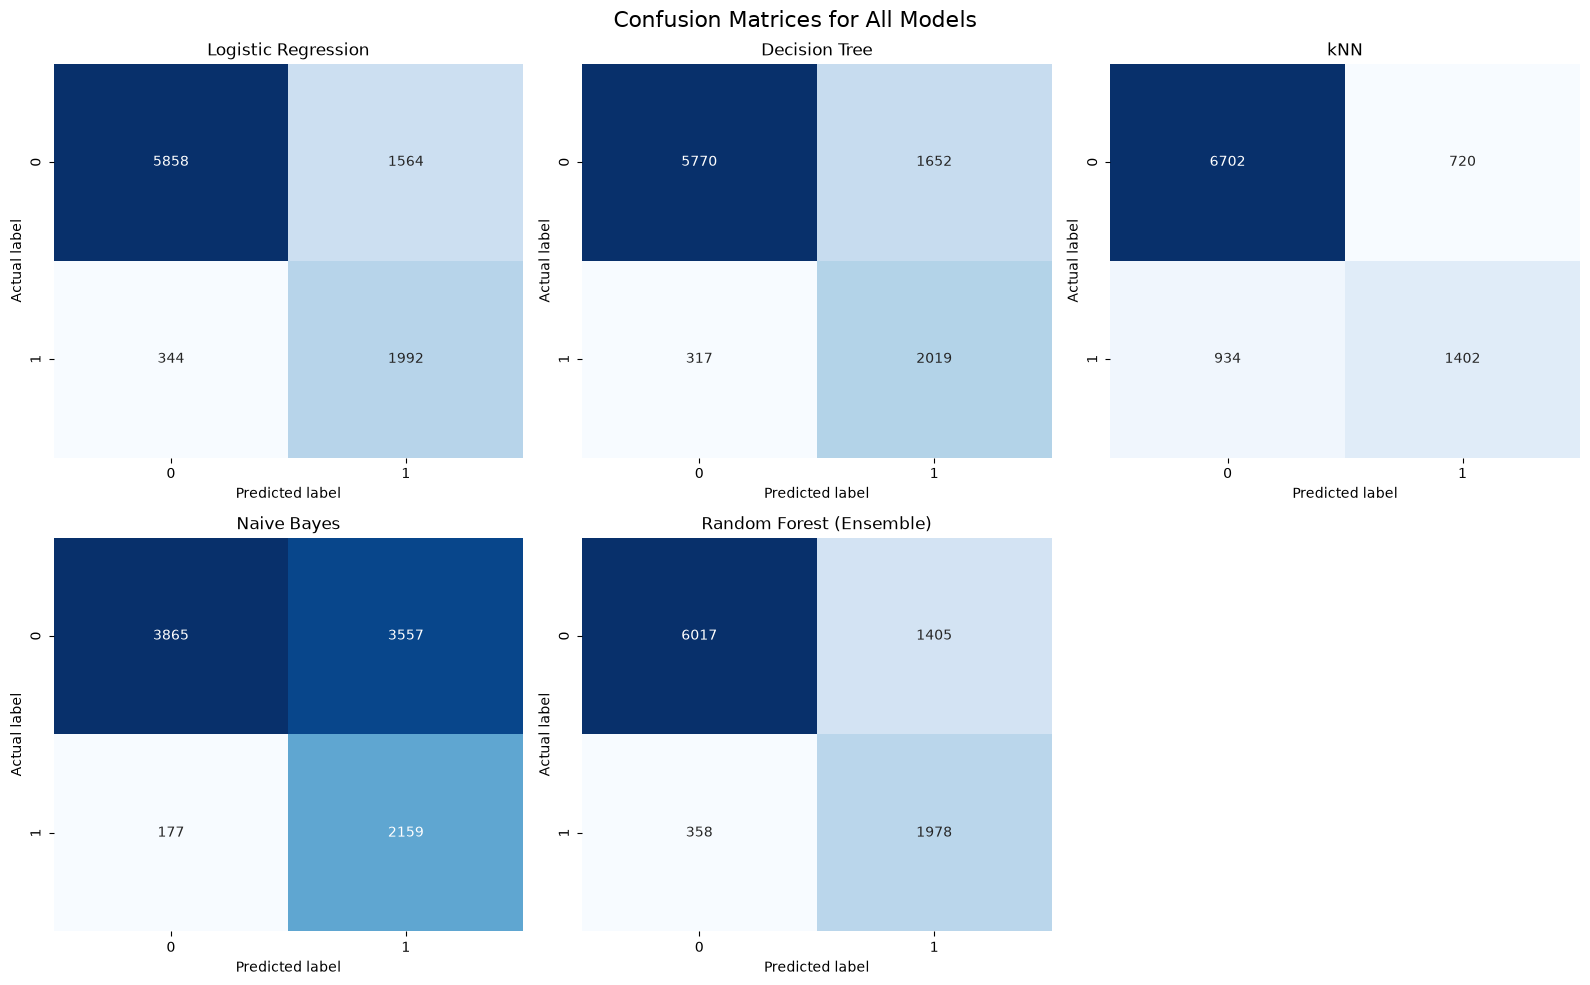


Logistic Regression
              precision    recall  f1-score   support

       <=50K       0.94      0.79      0.86      7422
        >50K       0.56      0.85      0.68      2336

    accuracy                           0.80      9758
   macro avg       0.75      0.82      0.77      9758
weighted avg       0.85      0.80      0.82      9758


Decision Tree
              precision    recall  f1-score   support

       <=50K       0.95      0.78      0.85      7422
        >50K       0.55      0.86      0.67      2336

    accuracy                           0.80      9758
   macro avg       0.75      0.82      0.76      9758
weighted avg       0.85      0.80      0.81      9758


kNN
              precision    recall  f1-score   support

       <=50K       0.88      0.90      0.89      7422
        >50K       0.66      0.60      0.63      2336

    accuracy                           0.83      9758
   macro avg       0.77      0.75      0.76      9758
weighted avg       0.83      0.83

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, (name, pipeline) in zip(axes, fitted_models.items()):
    y_pred = pipeline.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('Actual label')

for ax in axes[len(fitted_models):]:
    ax.axis('off')

plt.suptitle('Confusion Matrices for All Models', fontsize=16)
plt.tight_layout()
plt.show()

for name, pipeline in fitted_models.items():
    print('\n' + '=' * 70)
    print(name)
    print(classification_report(y_test, pipeline.predict(X_test),
                                target_names=['<=50K', '>50K'], zero_division=0))

## 6. Graph representation of all required metrics

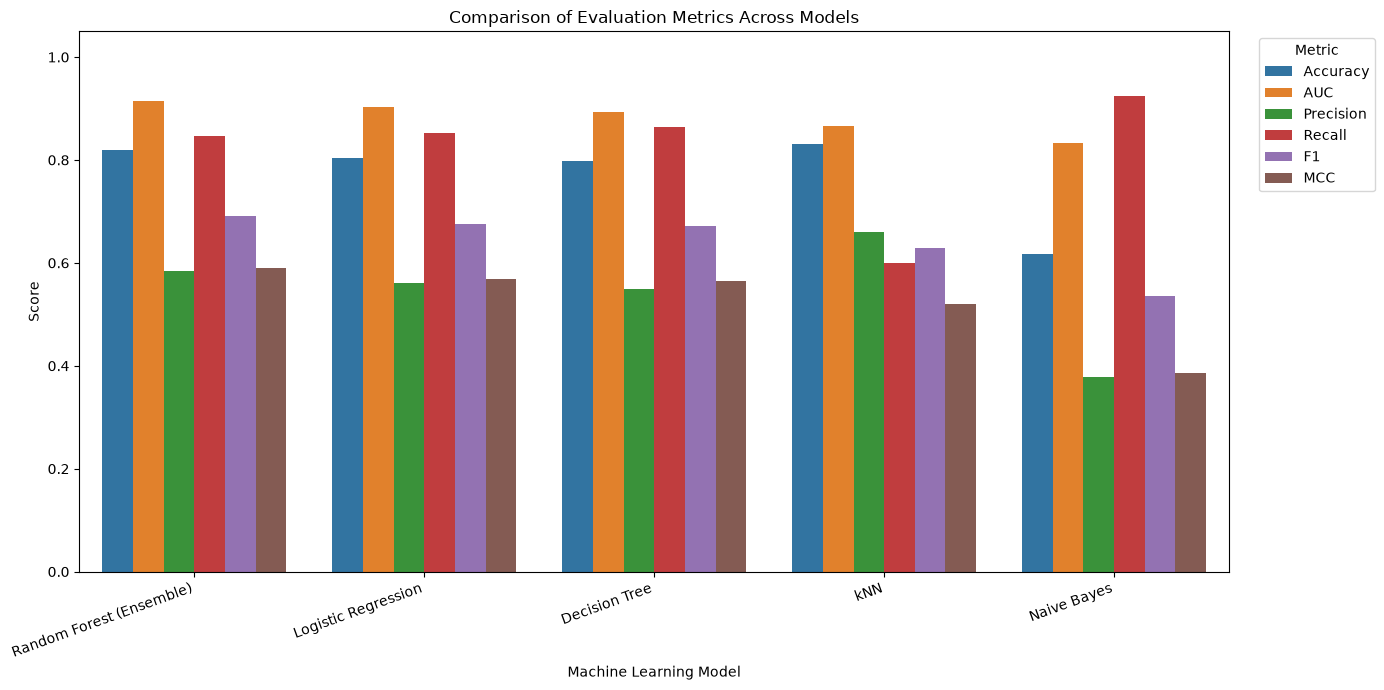

In [9]:
metrics_long = results_df.melt(
    id_vars='ML Model Name', var_name='Metric', value_name='Score'
)

plt.figure(figsize=(14, 7))
sns.barplot(data=metrics_long, x='ML Model Name', y='Score', hue='Metric')
plt.ylim(0, 1.05)
plt.title('Comparison of Evaluation Metrics Across Models')
plt.xlabel('Machine Learning Model')
plt.ylabel('Score')
plt.xticks(rotation=20, ha='right')
plt.legend(title='Metric', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('model_metrics_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

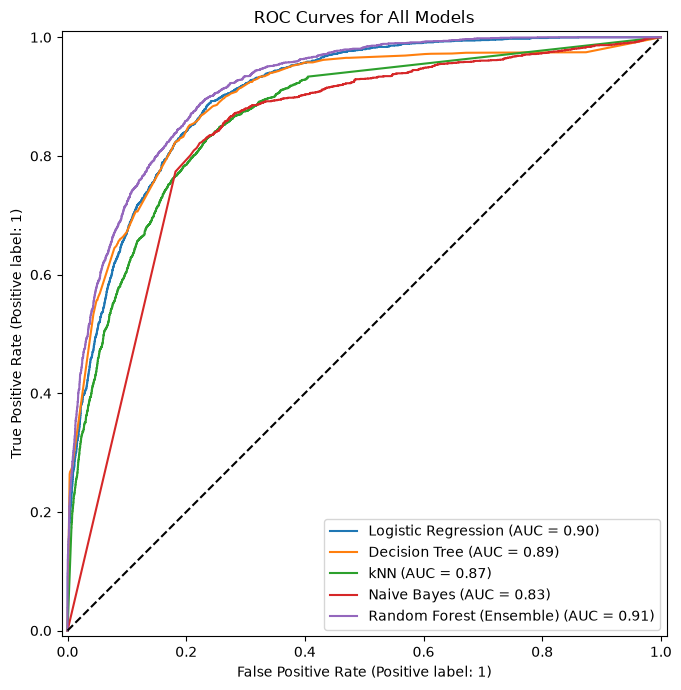

In [10]:
plt.figure(figsize=(9, 7))
ax = plt.gca()
for name, y_prob in roc_predictions.items():
    RocCurveDisplay.from_predictions(y_test, y_prob, name=name, ax=ax)
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.title('ROC Curves for All Models')
plt.tight_layout()
plt.savefig('roc_curves.png', dpi=200, bbox_inches='tight')
plt.show()

## 7. Data-driven observations and overall winner

The next cell automatically generates concise observations from the executed results. Before submission, read them and add your own explanation based on the metric table, ROC curves, confusion matrices, and classification reports.

In [11]:
best_f1_row = results_df.loc[results_df['F1'].idxmax()]
best_auc_row = results_df.loc[results_df['AUC'].idxmax()]
best_mcc_row = results_df.loc[results_df['MCC'].idxmax()]

for _, row in results_df.iterrows():
    print(
        f"{row['ML Model Name']}: Accuracy={row['Accuracy']:.3f}, "
        f"AUC={row['AUC']:.3f}, Precision={row['Precision']:.3f}, "
        f"Recall={row['Recall']:.3f}, F1={row['F1']:.3f}, MCC={row['MCC']:.3f}."
    )

print(f"\nHighest F1: {best_f1_row['ML Model Name']} ({best_f1_row['F1']:.3f})")
print(f"Highest AUC: {best_auc_row['ML Model Name']} ({best_auc_row['AUC']:.3f})")
print(f"Highest MCC: {best_mcc_row['ML Model Name']} ({best_mcc_row['MCC']:.3f})")

# Overall winner rule: highest MCC, because MCC uses all four confusion-matrix outcomes
# and is informative for imbalanced binary classification.
winner = best_mcc_row['ML Model Name']
print(f'Overall winner based on MCC: {winner}')

Random Forest (Ensemble): Accuracy=0.819, AUC=0.915, Precision=0.585, Recall=0.847, F1=0.692, MCC=0.589.
Logistic Regression: Accuracy=0.804, AUC=0.902, Precision=0.560, Recall=0.853, F1=0.676, MCC=0.569.
Decision Tree: Accuracy=0.798, AUC=0.894, Precision=0.550, Recall=0.864, F1=0.672, MCC=0.565.
kNN: Accuracy=0.830, AUC=0.867, Precision=0.661, Recall=0.600, F1=0.629, MCC=0.520.
Naive Bayes: Accuracy=0.617, AUC=0.833, Precision=0.378, Recall=0.924, F1=0.536, MCC=0.385.

Highest F1: Random Forest (Ensemble) (0.692)
Highest AUC: Random Forest (Ensemble) (0.915)
Highest MCC: Random Forest (Ensemble) (0.589)
Overall winner based on MCC: Random Forest (Ensemble)


### Suggested interpretation framework

- **Logistic Regression:** Strong interpretable baseline; compare its recall and AUC with nonlinear models.
- **Decision Tree:** Easy to explain but may overfit; compare training choices and test MCC.
- **kNN:** Sensitive to scaling and high-dimensional one-hot encoded data; note its runtime and recall.
- **Naive Bayes:** Fast probabilistic baseline; independence assumptions may limit performance.
- **Random Forest:** Usually handles nonlinear interactions well; check whether it leads on MCC, F1, or AUC.
- **Overall winner:** Use the executed results. Prefer MCC or F1 rather than accuracy alone because the target is imbalanced.

Replace this guidance with your own final, result-specific observations after running all cells.

## 8. Generated submission artifacts

After successful execution, the project folder contains:

- `test_data.csv`
- `model_comparison.csv`
- `model_metrics_comparison.png`
- `roc_curves.png`
- Five fitted `.joblib` model pipelines inside `model/`

Add the BITS Virtual Lab execution screenshot and insert your GitHub repository URL below.

**GitHub repository URL:** `PASTE_YOUR_GITHUB_REPOSITORY_LINK_HERE`

In [12]:
print('Files in current folder:')
for item in sorted(os.listdir('.')):
    print('-', item)

print('\nSaved model files:')
for item in sorted(os.listdir('model')):
    print('-', item)

Files in current folder:
- .venv
- 2026CT05174_ML_Assignment.executed.ipynb
- 2026CT05174_ML_Assignment.ipynb
- model
- model_comparison.csv
- model_metrics_comparison.png
- roc_curves.png
- test_data.csv

Saved model files:
- decision_tree.joblib
- knn.joblib
- logistic_regression.joblib
- naive_bayes.joblib
- random_forest_ensemble.joblib


## 9. Reproducibility statement

A fixed random seed of 42 is used for splitting and stochastic models. The test set is not used to fit preprocessing or models. All fitted transformations are contained within each saved pipeline, allowing the same preprocessing to be applied to future records.